In [1]:
dia = '2024-04-27'

## Importando as Bibliotecas

In [5]:
import pandas as pd
import numpy as np

import warnings
warnings.filterwarnings('ignore')

def drop_reset_index(df):
    df = df.dropna()
    df = df.reset_index(drop=True)
    df.index += 1
    return df

def plot_profit_acu(dataframe, title_text):
    dataframe['Profit_acu'] = dataframe.Profit.cumsum()
    n_apostas = dataframe.shape[0]
    profit = round(dataframe.Profit_acu.tail(1).item(), 2)
    ROI = round((dataframe.Profit_acu.tail(1) / n_apostas * 100).item(), 2)
    drawdown = dataframe['Profit_acu'] - dataframe['Profit_acu'].cummax()
    drawdown_maximo = round(drawdown.min(), 2)
    winrate_medio = round((dataframe['Profit'] > 0).mean() * 100, 2)
    desvio_padrao = round(dataframe['Profit'].std(), 2)
    dataframe.Profit_acu.plot(title=title_text, xlabel='Entradas', ylabel='Stakes')
    print("Metodo:",title_text)
    print("Profit:", profit, "stakes em", n_apostas, "jogos")
    print("ROI:", ROI, "%")
    print("Drawdown Maximo Acumulado:", drawdown_maximo)
    print("Winrate Medio:", winrate_medio, "%")
    print("Desvio Padrao:", desvio_padrao)
    print("")

def read_base():
    base = pd.read_csv("https://github.com/futpythontrader/YouTube/raw/main/Luke/Bases_de_Dados/Base_FutPythonPunter.csv")
    base["Date"] = pd.to_datetime(base["Date"])
    base = base[['League','Date','Home','Away','Goals_H','Goals_A','Odd_H','Odd_D','Odd_A']]
    base = drop_reset_index(base)
    return base

def read_jogos(dia):
    jogos_do_dia = pd.read_csv('https://github.com/futpythontrader/YouTube/blob/main/Jogos_do_Dia_FlashScore/'+str(dia)+'_Jogos_do_Dia_FlashScore.csv?raw=true')
    try:
        jogos_do_dia = jogos_do_dia[['League','Date','Time','Home','Away','Odd_H','Odd_D','Odd_A']]
        jogos_do_dia = drop_reset_index(jogos_do_dia)
    except:
        jogos_do_dia = jogos_do_dia[['League','Date','Time','Home','Away','FT_Odd_H','FT_Odd_D','FT_Odd_A']]
        jogos_do_dia.columns = ['League','Date','Time','Home','Away','Odd_H','Odd_D','Odd_A']
        jogos_do_dia = drop_reset_index(jogos_do_dia)

    return jogos_do_dia

## Importando a Base de Dados

In [6]:
base_orig = read_base()
flt = base_orig.Date < str(dia)
base = base_orig[flt]

In [7]:
df = base.copy()

df['VAR1'] = np.sqrt((df['Odd_H'] - df['Odd_A'])**2)
df['VAR2'] = np.degrees(np.arctan((df['Odd_A'] - df['Odd_H']) / 2))
df['VAR3'] = np.degrees(np.arctan((df['Odd_D'] - df['Odd_A']) / 2))

df['Lay_Home'] = np.where((df['Goals_H'] >  df['Goals_A']), 0, 1)
df['Lay_Draw'] = np.where((df['Goals_H'] == df['Goals_A']), 0, 1)
df['Lay_Away'] = np.where((df['Goals_H']  < df['Goals_A']), 0, 1)

## Backtesting

### Lay Home

Metodo: Lay Home
Profit: 53.76 stakes em 8408 jogos
ROI: 0.64 %
Drawdown Maximo Acumulado: -43.29
Winrate Medio: 85.69 %
Desvio Padrao: 0.41



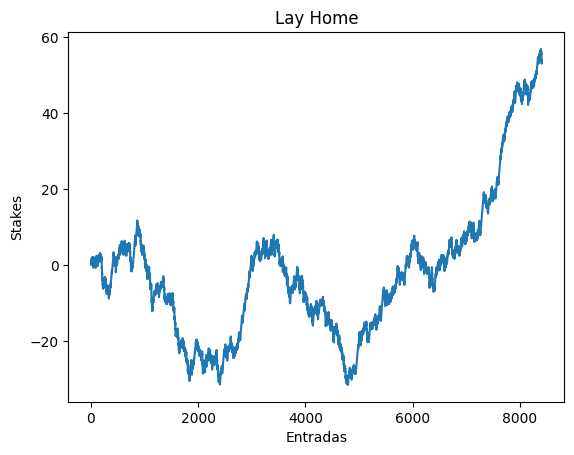

In [21]:
flt = (df.VAR1 >= 2.5) & (df.VAR2 <= -30) & (df.VAR3 >= 30)
df0 = df[flt]
df0 = drop_reset_index(df0)

df0['Profit'] = -1
df0.loc[(df0['Lay_Home'] == 1), 'Profit'] = 0.94 / (df0['Odd_H'] - 0.5)
plot_profit_acu(df0, 'Lay Home')

In [15]:
flt1 = (df0.Lay_Home == 0)
df1 = df0[flt1]
df1 = drop_reset_index(df1)

reds = len(df1)
greens = len(df0) - reds
reds / greens

0.1669673837612769

### Lay Away

Metodo: Lay Away
Profit: 124.51 stakes em 6376 jogos
ROI: 1.95 %
Drawdown Maximo Acumulado: -11.98
Winrate Medio: 93.62 %
Desvio Padrao: 0.27



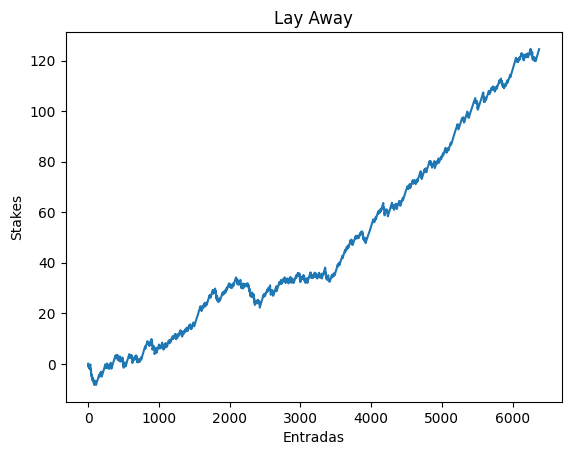

In [20]:
flt = (df.VAR1 >= 5) & (df.VAR2 >= 60) & (df.VAR3 <= -60)
df0 = df[flt]
df0 = drop_reset_index(df0)

df0['Profit'] = -1
df0.loc[(df0['Lay_Away'] == 1), 'Profit'] = 0.94 / (df0['Odd_A'] - 0.5)
plot_profit_acu(df0, 'Lay Away')

## Jogos do Dia

In [19]:
Jogos_do_Dia = read_jogos(dia)

Jogos_do_Dia['VAR1'] = np.sqrt((Jogos_do_Dia['Odd_H'] - Jogos_do_Dia['Odd_A'])**2)
Jogos_do_Dia['VAR2'] = np.degrees(np.arctan((Jogos_do_Dia['Odd_A'] - Jogos_do_Dia['Odd_H']) / 2))
Jogos_do_Dia['VAR3'] = np.degrees(np.arctan((Jogos_do_Dia['Odd_D'] - Jogos_do_Dia['Odd_A']) / 2))

flt1 = (Jogos_do_Dia.VAR1 >= 2.5) & (Jogos_do_Dia.VAR2 <= -30) & (Jogos_do_Dia.VAR3 >= 30)
Lay_Home = Jogos_do_Dia[flt1]
Lay_Home = drop_reset_index(Lay_Home)
Lay_Home['Entrada'] = 'Lay Home'

flt2 = (Jogos_do_Dia.VAR1 >= 5) & (Jogos_do_Dia.VAR2 >= 60) & (Jogos_do_Dia.VAR3 <= -60)
Lay_Away = Jogos_do_Dia[flt2]
Lay_Away = drop_reset_index(Lay_Away)
Lay_Away['Entrada'] = 'Lay Away'

Entradas = pd.concat([Lay_Home, Lay_Away])
Entradas = Entradas.sort_values(by='Time')
Entradas.drop_duplicates(subset=['Home','Away'], inplace=True)
Entradas = drop_reset_index(Entradas)
Entradas = Entradas[['Date','Time','League','Home','Away','Odd_H','Odd_D','Odd_A','Entrada']]
Entradas

,Date,Time,League,Home,Away,Odd_H,Odd_D,Odd_A,Entrada
1,27/04/2024,02:00,JAPAN - J2 LEAGUE,Kusatsu,V-Varen Nagasaki,4.75,3.50,1.80,Lay Home
2,27/04/2024,07:00,UKRAINE - PREMIER LEAGUE,Dnipro-1,Dyn. Kyiv,4.65,3.50,1.70,Lay Home
3,27/04/2024,08:30,ENGLAND - PREMIER LEAGUE,West Ham,Liverpool,4.75,4.75,1.57,Lay Home
4,27/04/2024,08:30,ENGLAND - LEAGUE ONE,Derby,Carlisle,1.20,6.50,15.00,Lay Away
5,27/04/2024,08:30,ENGLAND - LEAGUE ONE,Exeter,Oxford Utd,4.75,4.00,1.70,Lay Home
6,27/04/2024,08:30,ESTONIA - MEISTRILIIGA,Tallinna Kalev,Kalju,4.45,3.95,1.57,Lay Home
7,27/04/2024,09:00,SPAIN - LALIGA,Las Palmas,Girona,4.60,4.00,1.70,Lay Home
8,27/04/2024,09:00,ARMENIA - PREMIER LEAGUE,West Armenia,Ararat-Armenia,7.10,4.65,1.33,Lay Home
9,27/04/2024,09:30,AUSTRIA - 2. LIGA,Bregenz,Grazer AK,5.60,4.00,1.53,Lay Home
10,27/04/2024,09:30,UKRAINE - PREMIER LEAGUE,LNZ Cherkasy,Shakhtar Donetsk,9.25,4.85,1.29,Lay Home
